# 第 2 课 · 抽样误差、标准误与置信区间

商店在[第一课](01-binary-logit.ipynb)估计了顾客对价格的反应。如果换一批顾客，再按同样的规则报价，估计值会差多少？我们用模拟重做这项研究，观察只拿到一份样本时，怎样表达估计的不确定性。

**建议用时 60 分钟。** 依次运行单元格。学完后，你应能解释三个量之间的关系。

- **抽样误差（sampling error）**是这次估计值与真值的差，可能为正，也可能为负。
- **标准误（standard error）**是估计量在重复抽样下的标准差。单次分析报告的是对它的估计。
- **置信区间（confidence interval）**是用样本构造的区间。它的置信水平告诉我们，用同一方法反复构造区间时，包含真值的比例应接近多少。

## 1. 重做第一课的估计

顾客面对报价 $p_i$，购买条件仍是 $\alpha+\beta(p_i-8)+\varepsilon_i\geq 0$。真实参数 $\alpha=0.60$、$\beta=-0.55$ 保持固定。每位顾客独立地从 5 至 11 元的整数价中等概率抽到一个报价。效用冲击独立同分布，服从标准 Logistic 分布，并且与报价独立。给定报价的购买概率为

$$
q_i(\alpha,\beta)=\Lambda\big(\alpha+\beta(p_i-8)\big), \qquad
\Lambda(z)=\frac{1}{1+e^{-z}}.
$$

先把第一课的模拟和估计写成两个函数，方便后面重复使用。`draw_sample` 用真值**生成**购买记录。`fit_logit` 只读取报价和购买决策。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import minimize
from scipy.special import expit
from scipy.stats import norm

price_levels = np.arange(5, 12)
reference_price = 8.0
true_intercept = 0.60
true_slope = -0.55


def draw_sample(sample_size, rng):
    price = rng.choice(price_levels, size=sample_size)
    utility_shock = rng.logistic(size=sample_size)
    utility_difference = (
        true_intercept + true_slope * (price - reference_price) + utility_shock
    )
    purchased = (utility_difference >= 0).astype(int)
    return price, purchased

### 用一份样本估计标准误

第一课用优化器最小化**平均**负对数似然来求参数。估计标准误时，我们考察的是**总**负对数似然在估计值附近的曲率。曲率越大，参数稍一偏离估计值，对数似然就降得越快，数据通常能把参数估得更精确。

记 $\hat q_i=q_i(\hat\alpha,\hat\beta)$，令 $X$ 的两列为常数 $1$ 和中心化价格 $p_i-8$。二元 Logit 的总负对数似然在估计值处的二阶导数矩阵是 $J=X^\mathsf{T}WX$，其中 $W$ 的对角线元素为 $\hat q_i(1-\hat q_i)$。在本课的独立抽样和正确设定下，$J^{-1}$ 近似估计两个系数估计量的协方差矩阵。价格系数的标准误等于该矩阵第二个对角元素的平方根。因为 $J$ 汇总了全部 $n$ 位顾客的信息，如果从**平均**目标函数的二阶导数出发，需先乘以 $n$，再求逆。

代码检查价格是否有变动、两种结果是否都有观测，以及买家和未购买者能否仅靠某个价格阈值区分。完全分离时，阈值能严格区分两组。准完全分离时，允许部分观测正好落在阈值上。在完全分离或准完全分离时，有限的极大似然估计可能不存在。后面重复模拟会记录拟合失败的次数。

In [2]:
def fit_logit(price, purchased):
    purchase_prices = price[purchased == 1]
    nonpurchase_prices = price[purchased == 0]
    if purchase_prices.size == 0 or nonpurchase_prices.size == 0:
        raise RuntimeError("购买决策没有变动")
    if np.ptp(price) == 0:
        raise RuntimeError("报价没有变动")
    if (
        purchase_prices.min() >= nonpurchase_prices.max()
        or nonpurchase_prices.min() >= purchase_prices.max()
    ):
        raise RuntimeError("购买决策在价格上完全分离或准完全分离")

    design = np.column_stack((np.ones(price.size), price - reference_price))

    def negative_mean_log_likelihood(parameters):
        index = design @ parameters
        return np.logaddexp(0.0, (1 - 2 * purchased) * index).mean()

    def gradient(parameters):
        residual = expit(design @ parameters) - purchased
        return design.T @ residual / price.size

    fit = minimize(
        negative_mean_log_likelihood,
        x0=np.zeros(2),
        jac=gradient,
        method="BFGS",
        options={"gtol": 1e-7},
    )
    if not fit.success or not np.all(np.isfinite(fit.x)):
        raise RuntimeError(f"无法得到收敛的有限估计：{fit.message}")

    purchase_probability = expit(design @ fit.x)
    weight = purchase_probability * (1 - purchase_probability)
    information = design.T @ (weight[:, None] * design)
    if not np.all(np.isfinite(information)) or np.linalg.matrix_rank(information) < 2:
        raise RuntimeError("信息矩阵不可逆")
    try:
        covariance = np.linalg.solve(information, np.eye(2))
    except np.linalg.LinAlgError as error:
        raise RuntimeError("无法求信息矩阵的逆") from error
    variances = np.diag(covariance)
    if not np.all(np.isfinite(variances)) or np.any(variances <= 0):
        raise RuntimeError("无法计算有效的标准误")

    return fit.x, np.sqrt(variances)

### 构造一个 95% 置信区间

在大样本下，用标准正态分布的临界值构造双侧 Wald 置信区间。对 95% 的置信水平，两端各留 2.5%，临界值约为 $1.96$。区间为

$$
\hat\beta \;\pm\; 1.96\,\widehat{\mathrm{SE}}(\hat\beta).
$$

区间的中心取决于估计值，宽度取决于估计标准误与所选置信水平。下面使用与第一课相同的 2,000 人样本，先观察一次估计的抽样误差，再检查这个区间是否包含真值。

In [3]:
def wald_interval(estimate, standard_error, level=0.95):
    critical_value = norm.ppf((1 + level) / 2)
    half_width = critical_value * standard_error
    return estimate - half_width, estimate + half_width


lesson_one_sample = draw_sample(2_000, np.random.default_rng(120))
coefficients, standard_errors = fit_logit(*lesson_one_sample)
slope = coefficients[1]
slope_se = standard_errors[1]
lower, upper = wald_interval(slope, slope_se)

print(f"价格系数估计值 {slope:.4f}    模拟真值 {true_slope:.4f}")
print(f"抽样误差 {slope - true_slope:+.4f}    估计标准误 {slope_se:.4f}")
print(f"95% 置信区间 [{lower:.4f}, {upper:.4f}]")
print("区间包含真值" if lower <= true_slope <= upper else "区间未包含真值")

价格系数估计值 -0.5823    模拟真值 -0.5500
抽样误差 -0.0323    估计标准误 0.0300
95% 置信区间 [-0.6411, -0.5235]
区间包含真值


这次把价格系数估得比真值更负，误差约为 $-0.032$。标准误约为 $0.030$，表示同一设计下估计量的抽样波动约有多大。有了模拟真值才能算出这次的抽样误差。拿到实际数据时，仍可用给定模型计算标准误和置信区间。

## 2. 换样本，看看估计值怎么变

分别让每次研究访问 200 人和 2,000 人。每种样本量各做 500 次，每次重新独立生成报价和购买决策，再拟合同一个模型。两组使用不同的随机数流，生成数据所用的参数与报价规则保持相同。

循环遇到拟合失败时会记下一次失败。直方图和区间统计使用能够算出估计值与标准误的样本，汇总表会同时报告实际样本数与失败数。

In [4]:
def repeat_estimation(sample_size, repetitions, rng):
    results = []
    for _ in range(repetitions):
        price, purchased = draw_sample(sample_size, rng)
        try:
            coefficients, standard_errors = fit_logit(price, purchased)
        except RuntimeError:
            continue
        results.append((coefficients[1], standard_errors[1]))

    if len(results) < 2:
        raise RuntimeError("成功拟合的样本不足两次，无法比较抽样标准差")
    return np.array(results), repetitions - len(results)


sample_sizes = (200, 2_000)
repetitions = 500
child_seeds = np.random.SeedSequence(2026).spawn(len(sample_sizes))

experiments = {}
for sample_size, seed in zip(sample_sizes, child_seeds):
    experiments[sample_size] = repeat_estimation(
        sample_size, repetitions, np.random.default_rng(seed)
    )

### 比较价格系数估计值的抽样分布

每根柱表示多少次估计落在同一范围内。两张图共用横轴、纵轴和分箱，虚线标出同一个真值。先看两组的估计值都集中在哪里，再比较它们的分散程度。

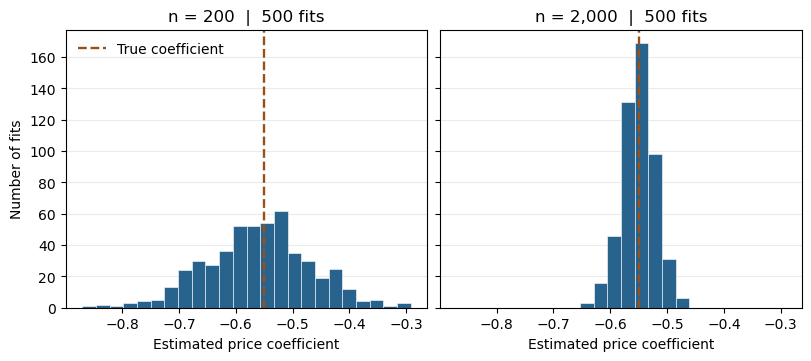

In [5]:
all_slopes = np.concatenate([results[:, 0] for results, _ in experiments.values()])
bins = np.histogram_bin_edges(all_slopes, bins=24)

fig, axes = plt.subplots(
    1, len(sample_sizes), figsize=(8, 3.5), sharex=True, sharey=True, layout="constrained"
)
for ax, sample_size in zip(axes, sample_sizes):
    draws, _ = experiments[sample_size]
    ax.hist(draws[:, 0], bins=bins, color="#28638e", edgecolor="white", linewidth=0.4)
    ax.axvline(true_slope, color="#9a4f18", ls="--", lw=1.7, label="True coefficient")
    ax.set(title=f"n = {sample_size:,}  |  {len(draws)} fits", xlabel="Estimated price coefficient")
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
axes[0].set_ylabel("Number of fits")
axes[0].legend(loc="upper left", frameon=False)
plt.show()

大样本的估计值更集中。我们可以把同一组里几百个估计值的**样本标准差**当作对抽样标准差的模拟估计。每次拟合也会给出一个**估计标准误**，只用那一次的报价与购买数据。把这些标准误取平均，就能和模拟得到的抽样标准差比较。两者接近，表示单次样本的标准误捕捉到了抽样波动的大致量级。

## 3. 用重复模拟理解区间覆盖率

给每份样本都构造一个 95% 置信区间，再数有多少区间包含 $-0.55$。用包含真值的区间数除以生成的有效区间数，得到**模拟覆盖率（simulation coverage rate）**。下面同时报告抽样标准差和区间宽度。表中的 `MC SE` 是由有限次重复模拟造成的覆盖率估计波动，随模拟次数增加而减小。

In [6]:
def summarize_intervals(draws, level=0.95):
    estimates, standard_errors = draws.T
    lower, upper = wald_interval(estimates, standard_errors, level)
    hits = (lower <= true_slope) & (true_slope <= upper)
    return lower, upper, hits


print(
    f"{'n':>6} {'Fits':>6} {'Failed':>7} {'Sim. SD':>9} {'Mean SE':>9} "
    f"{'Mean width':>11} {'Covered':>10} {'Coverage':>9} {'MC SE':>8}"
)
for sample_size, (draws, failures) in experiments.items():
    lower, upper, hits = summarize_intervals(draws)
    coverage = hits.mean()
    coverage_mc_se = np.sqrt(coverage * (1 - coverage) / len(hits))
    covered = f"{hits.sum()}/{len(hits)}"
    print(
        f"{sample_size:>6,} {len(draws):>6} {failures:>7} "
        f"{draws[:, 0].std(ddof=1):>9.4f} {draws[:, 1].mean():>9.4f} "
        f"{(upper - lower).mean():>11.4f} {covered:>10} "
        f"{coverage:>9.1%} {coverage_mc_se:>8.1%}"
    )

     n   Fits  Failed   Sim. SD   Mean SE  Mean width    Covered  Coverage    MC SE
   200    500       0    0.0928    0.0938      0.3675    476/500     95.2%     1.0%
 2,000    500       0    0.0290    0.0292      0.1143    472/500     94.4%     1.0%


默认设置下，两组的估计标准误均值都接近模拟抽样标准差。把每次的样本量从 200 增到 2,000，平均区间宽度从约 0.368 降到 0.114。在这个抽样设计中，样本量增加十倍，标准误大致缩小到原来的 $1/\sqrt{10}$。

两组的覆盖率分别是 **95.2%** 和 **94.4%**。覆盖率本身也是估计值。若覆盖概率在 95% 附近，用 500 次独立模拟估计它，标准误约是 1 个百分点。这个量描述模拟覆盖率的波动，和价格系数的估计标准误衡量的是两种不同的波动。

### 画出前 25 个区间

下图取小样本组按模拟顺序得到的前 25 个区间。每一行来自一份样本。竖直虚线标出固定的真值。圆点标出覆盖真值的区间的中心，叉号标出未覆盖的区间的中心。表中覆盖率使用全部有效区间。

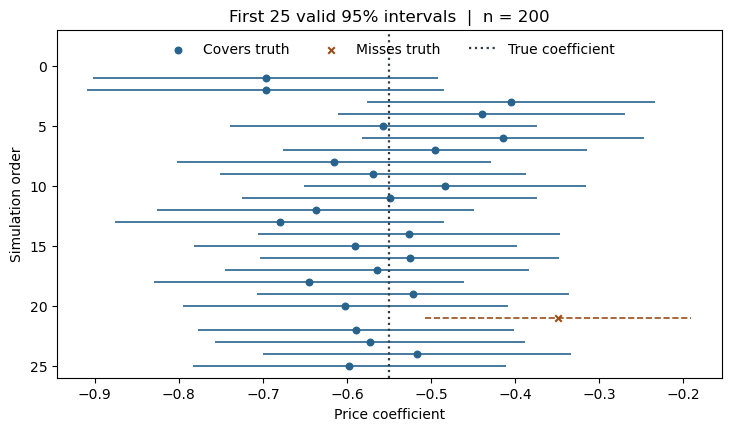

In [7]:
small_group, _ = experiments[sample_sizes[0]]
shown = small_group[:25]
lower, upper, hits = summarize_intervals(shown)
interval_specs = [
    (True, "#28638e", "o", "solid", "Covers truth"),
    (False, "#9a4f18", "x", "dashed", "Misses truth"),
]
row_numbers = np.arange(1, len(shown) + 1)

fig, ax = plt.subplots(figsize=(7.2, 4.2), layout="constrained")
for contains_truth, color, marker, line_style, label in interval_specs:
    selected = hits == contains_truth
    if selected.any():
        ax.hlines(
            row_numbers[selected], lower[selected], upper[selected],
            colors=color, linestyles=line_style, linewidth=1.2,
        )
        ax.scatter(
            shown[selected, 0], row_numbers[selected], color=color, marker=marker,
            s=22, label=label,
        )
ax.axvline(true_slope, color="#323c43", ls=":", lw=1.6, label="True coefficient")
ax.invert_yaxis()
ax.set(
    title=f"First {len(shown)} valid 95% intervals  |  n = {sample_sizes[0]:,}",
    xlabel="Price coefficient", ylabel="Simulation order",
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False)
ax.set_ylim(len(shown) + 1, -3)
plt.show()

**怎样说“95%”？** 如果不断按同一规则取样，并用同一方法计算区间，在本课的模型和大样本近似下，大约 95% 的区间应包含真值。换样本会改变区间。真值始终是同一个固定的数。看过某次的区间后，95% 仍指区间方法在重复抽样中的覆盖率。 [NIST 统计手册](https://www.itl.nist.gov/div898/handbook/prc/section1/prc14.htm)

## 动手练习

1. **一次估计与一次抽样误差。** 把单样本的种子从 120 改为你选的另一个数。重算价格系数、抽样误差、估计标准误与 95% 区间。比较两次结果，说明为什么换样本可以使抽样误差变号。
2. **只改变样本量。** 把 `sample_sizes` 改成 `(200, 800)`，运行第 2 节及后面的代码。比较两组的模拟抽样标准差和平均区间宽度。若每次抽到的人数变为四倍，标准误约变为原来的多少？说明这对单次估计误差能提供什么信息。
3. **只改变置信水平。** 对同一批 `draws`，分别运行 `summarize_intervals(draws, level=0.90)` 和 `summarize_intervals(draws, level=0.99)`，计算平均宽度与覆盖率。解释为什么比较不同置信水平时可以复用原来的拟合。
4. **分别看清两种波动。** 保持每次的样本量，先只运行 100 次模拟，再运行 1,000 次。比较两组汇总里的 `MC SE`。增加模拟次数，能否让某一次研究的置信区间变窄？